# Task 1: Skin lesion or skin? Binary segmentation of dermoscopy images

**Goal.** Train a **U-Net** that marks, for every pixel of a dermoscopy image, **lesion** or **skin**. This is binary segmentation: one output channel, two answers.
The lesion border matters in practice: its size and shape are used when doctors assess a lesion.

**Data.** [ISIC 2018 Task 1: Lesion Segmentation](https://challenge.isic-archive.com/data/) (official ISIC challenge data, CC-0 licence): 2,594 training images with lesion masks, 100 validation images and 1,000 test images. Every image shows one main lesion.
We use the **official validation set** to measure the model and never touch the test set.

##Names:
### Rufaida Kassem
### El-Zahraa
### Habiba

## 1. Download and look at the data
The masks and the validation set are small. The big training zip is read later, image by image.

In [8]:
import os, urllib.request, zipfile, glob
import matplotlib.pyplot as plt
import cv2
import numpy as np

# [colab-only] download the ISIC 2018 Task 1 data from the official ISIC archive
ROOT = "isic2018"
BASE = "https://isic-archive.s3.amazonaws.com/challenges/2018/"
os.makedirs(ROOT, exist_ok=True)

# The small files (masks of the training set, and the official validation set) are downloaded normally.
for f in ["ISIC2018_Task1_Training_GroundTruth.zip",        # 26 MB:  training masks
          "ISIC2018_Task1-2_Validation_Input.zip",          # 228 MB: validation images
          "ISIC2018_Task1_Validation_GroundTruth.zip"]:     # <1 MB:  validation masks
    path = os.path.join(ROOT, f)
    if not os.path.exists(path):
        print("downloading", f)
        urllib.request.urlretrieve(BASE + f, path)
    with zipfile.ZipFile(path) as z:
        z.extractall(ROOT)

# The training images are one 10.4 GB zip. We do NOT download all of it: the next cells read only the images we use.
TRAIN_INPUT_URL = BASE + "ISIC2018_Task1-2_Training_Input.zip"
print("done:", os.listdir(ROOT))

done: ['ISIC2018_Task1-2_Training_Input', 'ISIC2018_Task1_Training_GroundTruth', 'ISIC2018_Task1-2_Validation_Input.zip', 'ISIC2018_Task1_Validation_GroundTruth.zip', 'train_images_temp.zip', 'ISIC2018_Task1_Validation_GroundTruth', 'ISIC2018_Task1_Training_GroundTruth.zip', 'ISIC2018_Task1-2_Validation_Input']


In [9]:
def stem(p):
    """ISIC_0012345.jpg and ISIC_0012345_segmentation.png both give ISIC_0012345."""
    return os.path.basename(p).split(".")[0].replace("_segmentation", "")

rel = lambda p: os.path.relpath(p, ROOT)
masks = glob.glob(os.path.join(ROOT, "**", "*_segmentation.png"), recursive=True)
train_mask = {stem(p): p for p in masks if "Training" in rel(p)}
val_mask   = {stem(p): p for p in masks if "Validation" in rel(p)}
val_img    = {stem(p): p for p in glob.glob(os.path.join(ROOT, "**", "*.jpg"), recursive=True) if "Validation" in rel(p)}
val_names  = sorted(set(val_mask) & set(val_img))

print("training masks:", len(train_mask), "| validation pairs:", len(val_names))
assert train_mask and val_names, "Nothing found: look inside ROOT and check the folder names"
print("example:", rel(val_img[val_names[0]]), "<->", rel(val_mask[val_names[0]]))

training masks: 2594 | validation pairs: 100
example: ISIC2018_Task1-2_Validation_Input/ISIC_0012255.jpg <-> ISIC2018_Task1_Validation_GroundTruth/ISIC_0012255_segmentation.png


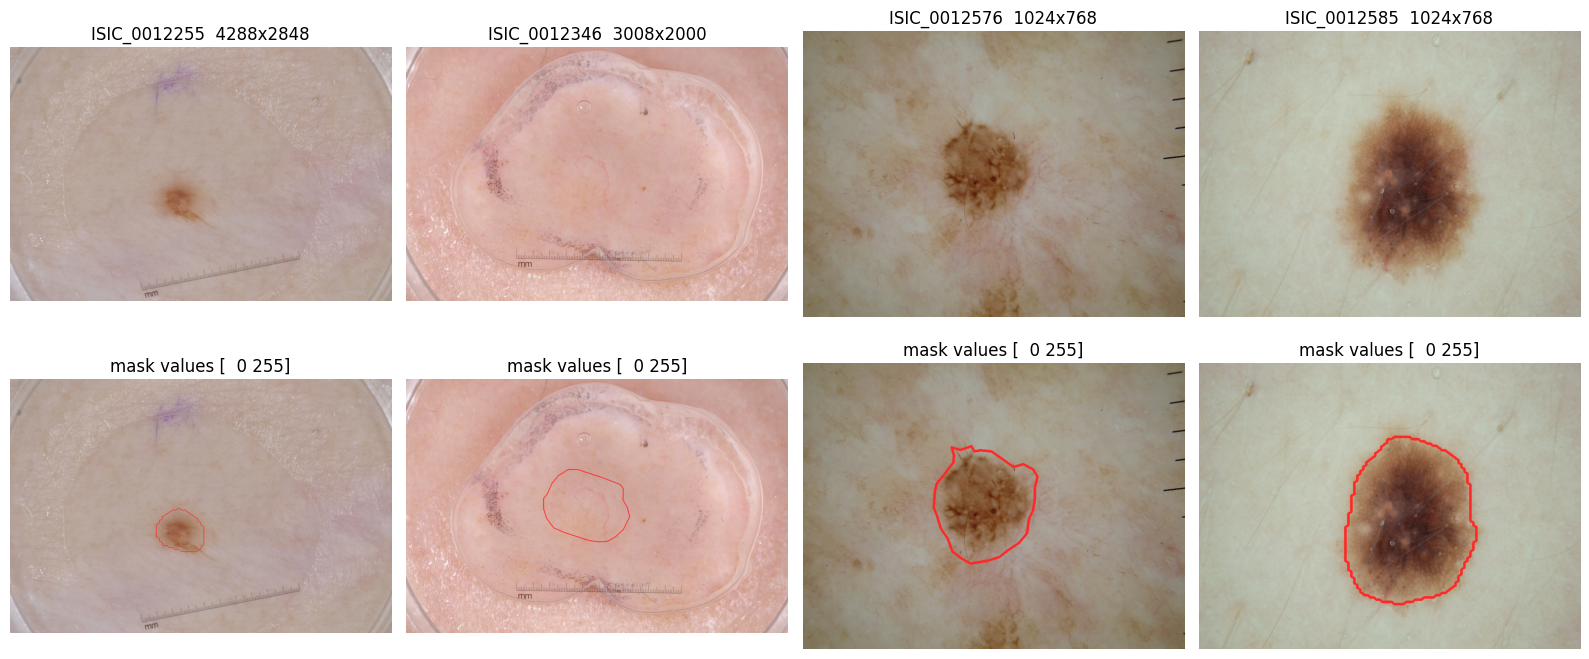

In [10]:
def outline(img, mask, color, t=3):
    out = img.copy()
    cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(out, cnts, -1, color, t)
    return out

fig, ax = plt.subplots(2, 4, figsize=(16, 7))
for k, n in enumerate(val_names[:4]):
    img = cv2.cvtColor(cv2.imread(val_img[n]), cv2.COLOR_BGR2RGB)
    m = cv2.imread(val_mask[n], cv2.IMREAD_GRAYSCALE)
    ax[0, k].imshow(img); ax[0, k].set_title(f"{n}  {img.shape[1]}x{img.shape[0]}"); ax[0, k].axis("off")
    ax[1, k].imshow(outline(img, m > 127, (255, 40, 40), 6)); ax[1, k].set_title(f"mask values {np.unique(m)}"); ax[1, k].axis("off")
plt.tight_layout(); plt.show()

Look at the pictures: **different sizes, hair, ruler marks, lesions with a soft border.** Real medical data is messy, and two doctors would not draw exactly the same border.

In [11]:
!pip install -q torch torchvision segmentation-models-pytorch

In [12]:
import torch
from torch.utils.data import Dataset
import cv2
import numpy as np

class CustomSegmentationDataset(Dataset):
    def __init__(self, image_paths, mask_paths, size=(256, 256)):
        """
        Args:
            image_paths (list): List of paths to the input images.
            mask_paths (list): List of paths to the ground truth masks.
            size (tuple): Target size for resizing (width, height).
        """
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.size = size

    def __len__(self):
        # Return total number of samples
        return len(self.image_paths)

    def __getitem__(self, idx):
        # 1. Fetch image and mask paths
        img_path = self.image_paths[idx]
        mask_path = self.mask_paths[idx]

        # 2. Load image and mask
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        # 3. Resize
        image = cv2.resize(image, self.size)
        mask = cv2.resize(mask, self.size, interpolation=cv2.INTER_NEAREST)

        # 4. Normalize and convert format (HWC to CHW)
        image = image.transpose(2, 0, 1).astype(np.float32) / 255.0
        mask = (mask > 127).astype(np.float32)
        mask = np.expand_dims(mask, axis=0)  # Shape becomes (1, H, W)

        # 5. Return as PyTorch Tensors
        return torch.tensor(image), torch.tensor(mask)

In [14]:
import urllib.request
import zipfile
import io
import os
import cv2
import numpy as np
import torch
from torch.utils.data import DataLoader

# 1. We select our subset of 1000 training names
train_names_subset = sorted(list(train_mask.keys()))[:1000]
set_names_subset = set(train_names_subset)

# Create a directory on local disk to store the extracted images
LOCAL_TRAIN_DIR = os.path.join(ROOT, "ISIC2018_Task1-2_Training_Input")
os.makedirs(LOCAL_TRAIN_DIR, exist_ok=True)

def download_and_extract_subset(url, target_names, output_dir):
    # Count how many target images we have already saved to disk
    existing_files = {os.path.splitext(f)[0] for f in os.listdir(output_dir)}
    needed_names = target_names - existing_files

    if not needed_names:
        print("All 1,000 training images are already present on disk!")
        return

    temp_zip_path = os.path.join(ROOT, "train_images_temp.zip")

    # If the zip exists but is broken or empty, remove it so we can download it fresh
    if os.path.exists(temp_zip_path):
        try:
            with zipfile.ZipFile(temp_zip_path, 'r') as z:
                _ = z.namelist()[0]
        except Exception:
            print("Removing corrupted temporary zip file from disk...")
            os.remove(temp_zip_path)

    if not os.path.exists(temp_zip_path):
        print(f"Streaming remote archive to extract {len(needed_names)} missing images directly to disk...")
        req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req) as response:
            print("Downloading the archive directly to disk (safely keeping RAM free)... ")
            with open(temp_zip_path, 'wb') as f:
                chunk_size = 1024 * 1024 * 16 # 16 MB chunks
                downloaded = 0
                while True:
                    chunk = response.read(chunk_size)
                    if not chunk:
                        break
                    f.write(chunk)
                    downloaded += len(chunk)
                    print(f"\rDownloaded: {downloaded / (1024*1024):.1f} MB to disk (RAM remains empty)", end="")
            print("\nDownload complete!")

    print("Extracting our 1,000 images from the local zip file...")
    with zipfile.ZipFile(temp_zip_path, 'r') as z:
        all_files = z.namelist()
        # Filter files belonging to our target 1,000 subset
        files_to_extract = [
            f for f in all_files
            if f.startswith("ISIC2018_Task1-2_Training_Input/") and
            os.path.basename(f).replace(".jpg", "") in needed_names
        ]

        for i, f in enumerate(files_to_extract):
            z.extract(f, path=ROOT)
            if (i + 1) % 100 == 0:
                print(f"Extracted {i + 1}/{len(files_to_extract)} images...")

# Safely run the download and extraction onto disk
download_and_extract_subset(TRAIN_INPUT_URL, set_names_subset, LOCAL_TRAIN_DIR)

class LocalTrainingDataset(CustomSegmentationDataset):
    def __init__(self, names, mask_dict, size=(256, 256)):
        self.names = names
        self.mask_dict = mask_dict
        self.size = size

    def __len__(self):
        return len(self.names)

    def __getitem__(self, idx):
        name = self.names[idx]

        # Load image directly from disk
        img_path = os.path.join(LOCAL_TRAIN_DIR, f"{name}.jpg")
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Load local training mask
        mask_path = self.mask_dict[name]
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        # Resize
        image = cv2.resize(image, self.size)
        mask = cv2.resize(mask, self.size, interpolation=cv2.INTER_NEAREST)

        # Transform
        image = image.transpose(2, 0, 1).astype(np.float32) / 255.0
        mask = (mask > 127).astype(np.float32)
        mask = np.expand_dims(mask, axis=0)

        return torch.tensor(image), torch.tensor(mask)

# Instantiate training dataset using our highly optimized disk-backed loader
train_ds = LocalTrainingDataset(train_names_subset, train_mask, size=(256, 256))
train_loader = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=0)

Removing corrupted temporary zip file from disk...
Streaming remote archive to extract 1000 missing images directly to disk...
Downloaded: 10648.1 MB to disk (RAM remains empty)
Download complete!
Extracting our 1,000 images from the local zip file...
Extracted 100/1000 images...
Extracted 200/1000 images...
Extracted 300/1000 images...
Extracted 400/1000 images...
Extracted 500/1000 images...
Extracted 600/1000 images...
Extracted 700/1000 images...
Extracted 800/1000 images...
Extracted 900/1000 images...
Extracted 1000/1000 images...


In [15]:
import torch
import torch.nn as nn
from torch.optim import Adam
import segmentation_models_pytorch as smp

model = smp.Unet('resnet18', encoder_weights='imagenet', classes=1)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

In [19]:
# 1. Set device for accelerated training (GPU if available)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Move model to the selected device
model = model.to(device)

# Re-initialize the optimizer *after* moving the model to the GPU
# This ensures the optimizer's internal state tensors are created on the correct device.
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# 2. Create the validation dataset and loader
# Map val_names to their actual paths on disk
val_image_paths = [val_img[name] for name in val_names]
val_mask_paths = [val_mask[name] for name in val_names]

val_ds = CustomSegmentationDataset(val_image_paths, val_mask_paths, size=(256, 256))
val_loader = DataLoader(val_ds, batch_size=8, shuffle=False, num_workers=0)

num_epochs = 3
print("Starting training...\n")

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    total_correct_pixels = 0
    total_pixels = 0

    for batch_idx, (images, masks) in enumerate(train_loader):
        # Move tensors to GPU/CPU
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        # Calculate training pixel accuracy
        preds = (outputs > 0.0).float()
        correct = (preds == masks).sum().item()
        total_correct_pixels += correct
        total_pixels += masks.numel()

        # Print progress every 20 batches
        if (batch_idx + 1) % 20 == 0:
            batch_acc = correct / masks.numel()
            print(f"Epoch [{epoch+1}/{num_epochs}], Batch [{batch_idx+1}/{len(train_loader)}], Batch Loss: {loss.item():.4f}, Batch Pixel Acc: {batch_acc*100:.2f}%")

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = total_correct_pixels / total_pixels
    print(f"\n--- Epoch {epoch+1}/{num_epochs} Complete: Avg Training Loss: {epoch_loss:.4f} | Training Pixel Acc: {epoch_acc*100:.2f}% ---")

    # Validation Phase
    model.eval()
    val_loss = 0.0
    val_correct_pixels = 0
    val_pixels = 0
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            loss = criterion(outputs, masks)
            val_loss += loss.item() * images.size(0)

            # Calculate validation pixel accuracy
            preds = (outputs > 0.0).float()
            val_correct_pixels += (preds == masks).sum().item()
            val_pixels += masks.numel()

        val_loss /= len(val_loader.dataset)
        val_acc = val_correct_pixels / val_pixels
        print(f"Validation Loss: {val_loss:.4f} | Validation Pixel Acc: {val_acc*100:.2f}%\n")

Using device: cuda
Starting training...

Epoch [1/3], Batch [20/125], Batch Loss: 0.0704, Batch Pixel Acc: 97.83%
Epoch [1/3], Batch [40/125], Batch Loss: 0.1412, Batch Pixel Acc: 94.24%
Epoch [1/3], Batch [60/125], Batch Loss: 0.2394, Batch Pixel Acc: 86.59%
Epoch [1/3], Batch [80/125], Batch Loss: 0.1467, Batch Pixel Acc: 94.28%
Epoch [1/3], Batch [100/125], Batch Loss: 0.1037, Batch Pixel Acc: 96.59%
Epoch [1/3], Batch [120/125], Batch Loss: 0.1185, Batch Pixel Acc: 95.25%

--- Epoch 1/3 Complete: Avg Training Loss: 0.1458 | Training Pixel Acc: 94.23% ---
Validation Loss: 0.2002 | Validation Pixel Acc: 91.02%

Epoch [2/3], Batch [20/125], Batch Loss: 0.1310, Batch Pixel Acc: 95.31%
Epoch [2/3], Batch [40/125], Batch Loss: 0.1287, Batch Pixel Acc: 94.18%
Epoch [2/3], Batch [60/125], Batch Loss: 0.1705, Batch Pixel Acc: 93.07%
Epoch [2/3], Batch [80/125], Batch Loss: 0.1030, Batch Pixel Acc: 96.38%
Epoch [2/3], Batch [100/125], Batch Loss: 0.1061, Batch Pixel Acc: 95.85%
Epoch [2/3], 

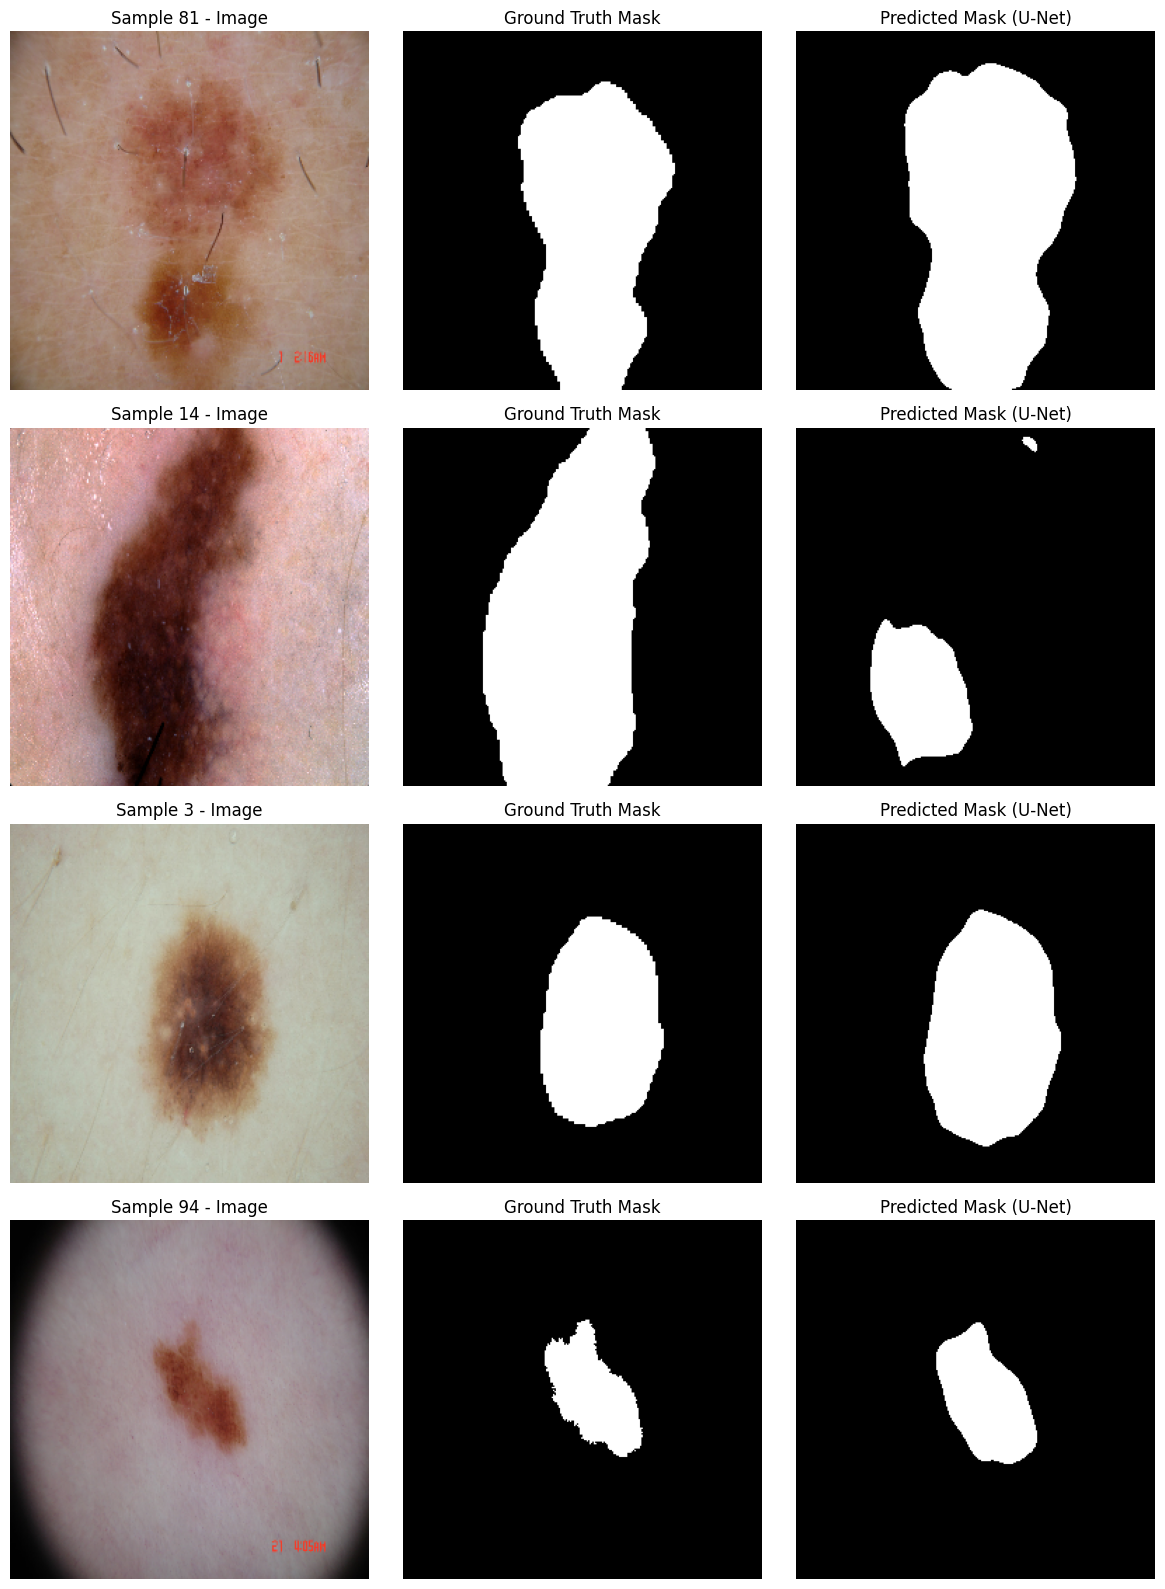

In [20]:
import matplotlib.pyplot as plt
import random

# Put model in evaluation mode
model.eval()

# Select 4 random sample indices from the validation set
random.seed(42)
sample_indices = random.sample(range(len(val_ds)), 4)

fig, axes = plt.subplots(4, 3, figsize=(12, 16))

with torch.no_grad():
    for i, idx in enumerate(sample_indices):
        # Get original image & mask tensor
        image_tensor, mask_tensor = val_ds[idx]

        # Prepare input for model (add batch dimension and move to device)
        input_tensor = image_tensor.unsqueeze(0).to(device)

        # Forward pass
        logits = model(input_tensor)
        # Apply threshold to sigmoid output
        pred_mask = (logits > 0.0).float().cpu().squeeze(0).squeeze(0).numpy()

        # Convert image tensor back to HWC format for plotting
        original_img = image_tensor.numpy().transpose(1, 2, 0)
        true_mask = mask_tensor.squeeze(0).numpy()

        # Plot original image
        axes[i, 0].imshow(original_img)
        axes[i, 0].set_title(f"Sample {idx} - Image")
        axes[i, 0].axis("off")

        # Plot ground truth mask
        axes[i, 1].imshow(true_mask, cmap="gray")
        axes[i, 1].set_title("Ground Truth Mask")
        axes[i, 1].axis("off")

        # Plot predicted mask
        axes[i, 2].imshow(pred_mask, cmap="gray")
        axes[i, 2].set_title("Predicted Mask (U-Net)")
        axes[i, 2].axis("off")

plt.tight_layout()
plt.show()